<a href="https://colab.research.google.com/github/meghawwk/discount-trap-superstore-analysis/blob/main/discount-trap/notebooks/analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#1.Load & inspect data
df = pd.read_csv(r"Sample - Superstore.csv", encoding="latin-1")
df.shape
df.info()

df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [3]:
import os
print(os.getcwd())
print(os.listdir())

/content
['.config', 'Sample - Superstore.csv', 'sample_data']


In [4]:
#2.Clean the data
df.columns = df.columns.str.strip().str.replace(" ", "_").str.replace("-", "_")
df["Order_Date"] = pd.to_datetime(df["Order_Date"])
df["Year"] = df["Order_Date"].dt.year
df["Month"] = df["Order_Date"].dt.to_period("M")

print(df.isnull().sum())
print(df.duplicated().sum())
df = df.drop_duplicates()

Row_ID           0
Order_ID         0
Order_Date       0
Ship_Date        0
Ship_Mode        0
Customer_ID      0
Customer_Name    0
Segment          0
Country          0
City             0
State            0
Postal_Code      0
Region           0
Product_ID       0
Category         0
Sub_Category     0
Product_Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
Year             0
Month            0
dtype: int64
0


In [5]:
#3.Create key metrics

df["Profit_Margin"]=df["Profit"]/df["Sales"]
df["Is_Loss"]=df["Profit"] < 0

#bucket discounts
bins=[-0.01, 0, 0.10, 0.20, 0.30, 0.50, 1]
labels=["0%", "1-10%", "11-20%",
        "21-30%", "31-50%", "50%+"]
df["Discount_Band"]=pd.cut(df['Discount'], bins=bins, labels=labels)

            Sales      Profit   Margin_%
Year                                    
2014  484247.4981  49543.9741  10.231126
2015  470532.5090  61618.6037  13.095504
2016  609205.5980  81795.1743  13.426530
2017  733215.2552  93439.2696  12.743771


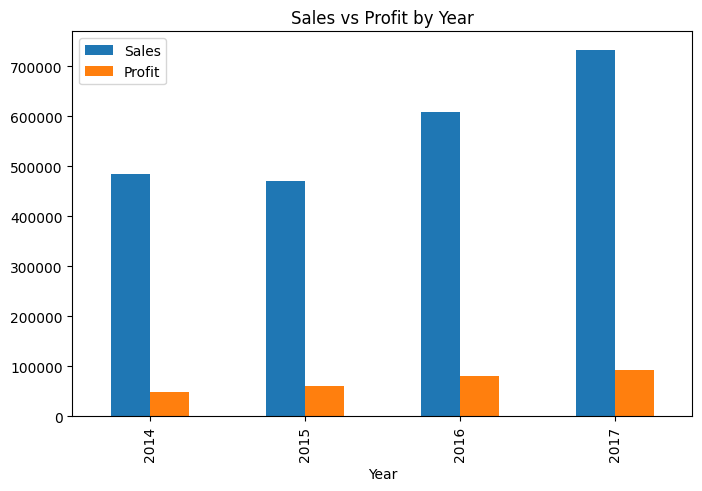

In [6]:
#4.Establish the "growth story"
#Show that revenue looks healthy first, so the trap is visible later.

yearly= df.groupby("Year")[["Sales","Profit"]].sum()
yearly["Margin_%"]= yearly["Profit"] / yearly["Sales"] * 100
print(yearly)

yearly[["Sales","Profit"]].plot(kind="bar", figsize=(8,5), title="Sales vs Profit by Year")
plt.show()

In [7]:
#acc. to plot Sales growing faster than profit, or margin flat or shrinking.

               Orders         Sales       Profit  Avg_Margin  Loss_Rate
Discount_Band                                                          
0%               4798  1.087908e+06  320987.6032    0.340160   0.000000
1-10%              94  5.436935e+04    9029.1770    0.155792   0.042553
11-20%           3709  7.921529e+05   91756.2975    0.174839   0.139930
21-30%            227  1.032267e+05  -10369.2774   -0.115481   0.916300
31-50%            310  1.953148e+05  -48447.7273   -0.296062   0.916129
50%+              856  6.422874e+04  -76559.0513   -1.138785   1.000000


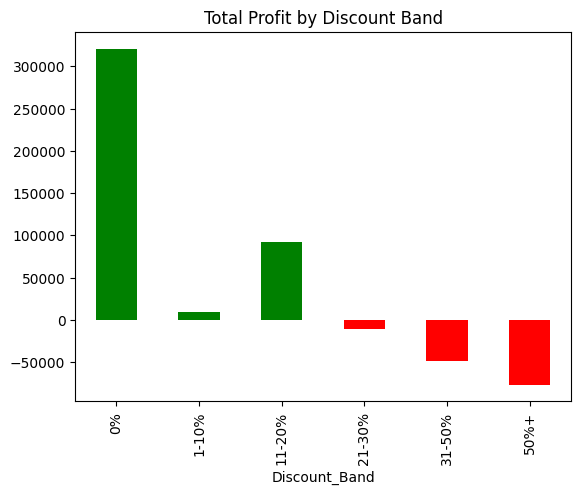

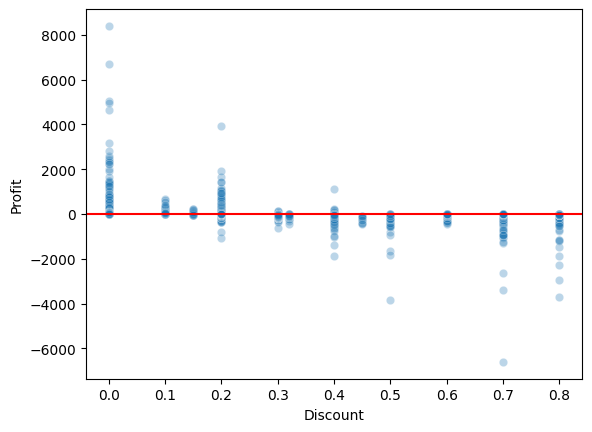

In [8]:
#5.Discount vs Profit (main analysis)

band= df.groupby("Discount_Band", observed=True).agg(
    Orders=("Order_ID", "count"),
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Avg_Margin=("Profit_Margin", "mean"),
    Loss_Rate=("Is_Loss", "mean")
)
print(band)

band["Profit"].plot(kind="bar", color=np.where(band["Profit"]<0, "red", "green"),
                    title="Total Profit by Discount Band")
plt.show()

sns.scatterplot(data=df, x="Discount", y="Profit", alpha=0.3)
plt.axhline(0, color="red")
plt.show()

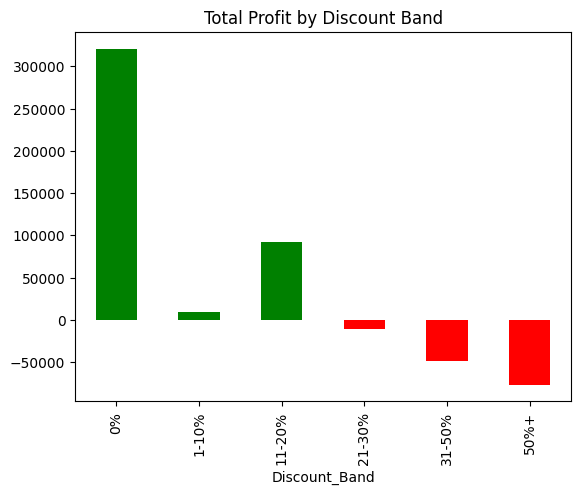

In [9]:
band["Profit"].plot(kind="bar", color=np.where(band["Profit"]<0, "red", "green"),
                    title="Total Profit by Discount Band")
plt.show()

In [10]:
#check here, discount level where profit flips -ve (the break-even point)
#and the loss rate climbing with discount

                    Sales      Profit  Avg_Discount
Sub_Category                                       
Tables        206965.5320 -17725.4811      0.261285
Bookcases     114879.9963  -3472.5560      0.211140
Supplies       46673.5380  -1189.0995      0.076842
Fasteners       3024.2800    949.5182      0.082028
Machines      189238.6310   3384.7569      0.306087
Labels         12486.3120   5546.2540      0.068681
Art            27118.7920   6527.7870      0.074874
Envelopes      16476.4020   6964.1767      0.080315
Furnishings    91705.1640  13059.1436      0.138349
Appliances    107532.1610  18138.0054      0.166524
Storage       223843.6080  21278.8264      0.074704
Chairs        328449.1030  26590.1663      0.170178
Binders       203412.7330  30221.7633      0.372292
Paper          78479.2060  34053.5693      0.074891
Accessories   167380.3180  41936.6357      0.078452
Phones        330007.0540  44515.7306      0.154556
Copiers       149528.0300  55617.8249      0.161765


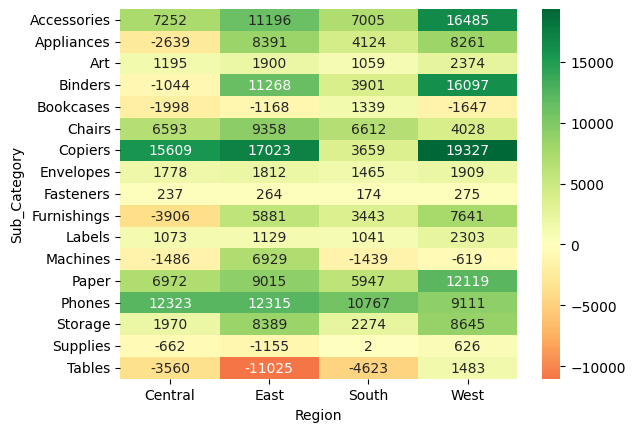

In [11]:
#6.Find where the damage is concentrated

#By sub-category
sub= df.groupby("Sub_Category").agg(
    Sales=("Sales","sum"),
    Profit=("Profit","sum"),
    Avg_Discount=("Discount","mean")
).sort_values("Profit")
print(sub)

#By region
df.groupby("Region").agg(
    Sales=("Sales","sum"),
    Profit=("Profit","sum"),
    Avg_Discount=("Discount","mean")
)

#Heatmap: region where x sub-category profit
pivot= df.pivot_table(values="Profit", index="Sub_Category", columns="Region", aggfunc="sum")
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="RdYlGn", center=0)
plt.show()


In [12]:
#here, sub-categories with high sales but -ve profit, and regions that discount heavily

In [13]:
#7.Quantify the cost of trap

loss_orders= df[df["Profit"] < 0]
print("Loss-making orders %:", len(loss_orders) / len(df) * 100)
print("Total profit lost:", loss_orders["Profit"].sum())
print("Avg disount on loss orders:", loss_orders["Discount"].mean())
print("Avg disount on profitable orders:", df[df["Profit"]>0]["Discount"].mean())

#what-if : cap discounts at 20%
df["Capped_Profit_Est"]= np.where(df['Discount'] > 0.20, np.nan, df["Profit"])
high_disc= df[df['Discount'] > 0.20]
print("Sales from >20% discount orders:", high_disc["Sales"].sum())
print("Profit from those orders:", high_disc["Profit"].sum())

Loss-making orders %: 18.721232739643785
Total profit lost: -156131.2857
Avg disount on loss orders: 0.48088722608230894
Avg disount on profitable orders: 0.08104368329610324
Sales from >20% discount orders: 362770.1498
Profit from those orders: -135376.056


In [14]:
#headline no: “X% of sales came from heavy-discount orders that lost Y in profit.”

In [15]:
#8.Check whether discounts even drive volume
#This tests whether discounting is justified at all

print(df.groupby("Discount_Band", observed=True)["Quantity"].mean())
print(df[["Discount","Quantity", "Sales", "Profit"]].corr())

Discount_Band
0%        3.807211
1-10%     3.968085
11-20%    3.736317
21-30%    3.740088
31-50%    3.796774
50%+      3.912383
Name: Quantity, dtype: float64
          Discount  Quantity     Sales    Profit
Discount  1.000000  0.008623 -0.028190 -0.219487
Quantity  0.008623  1.000000  0.200795  0.066253
Sales    -0.028190  0.200795  1.000000  0.479064
Profit   -0.219487  0.066253  0.479064  1.000000


In [16]:
#check : A weak or no increase in quantity per order at higher discounts,
#but a strongly negative discount-profit correlation. That is the trap.

In [17]:
#9.1 find the break-even discount level:
disc = df.groupby("Discount").agg(
    Orders=("Order_ID", "count"),
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
)
disc["Margin_%"] = (disc["Profit"] / disc["Sales"] * 100).round(1)
print(disc)

          Orders         Sales       Profit  Margin_%
Discount                                             
0.00        4798  1.087908e+06  320987.6032      29.5
0.10          94  5.436935e+04    9029.1770      16.6
0.15          52  2.755852e+04    1418.9915       5.1
0.20        3657  7.645944e+05   90337.3060      11.8
0.30         227  1.032267e+05  -10369.2774     -10.0
0.32          27  1.449346e+04   -2391.1377     -16.5
0.40         206  1.164178e+05  -23057.0504     -19.8
0.45          11  5.484974e+03   -2493.1111     -45.5
0.50          66  5.891854e+04  -20506.4281     -34.8
0.60         138  6.644700e+03   -5944.6552     -89.5
0.70         418  4.062028e+04  -40075.3569     -98.7
0.80         300  1.696376e+04  -30539.0392    -180.0


In [18]:
#highest discount level where Profit is still positive: at 20%

In [19]:
#9.2 impact of discount cap

cap = 0.20
high = df[df["Discount"] > cap].copy()

cost = high["Sales"] - high["Profit"]              # implied cost
list_price = high["Sales"] / (1 - high["Discount"])  # price before discount
new_profit = list_price * (1 - cap) - cost           # profit if discount were capped

actual = high["Profit"].sum()
simulated = new_profit.sum()

print("Orders above cap:", len(high))
print("Actual profit on those orders:", round(actual))
print("Simulated profit with cap:", round(simulated))
print("Estimated profit recovered:", round(simulated - actual))

Orders above cap: 1393
Actual profit on those orders: -135376
Simulated profit with cap: 83815
Estimated profit recovered: 219191


In [20]:
#9.3 Identify loss-making sub-categories

sub = df.groupby("Sub_Category").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Avg_Discount=("Discount", "mean")
)
sub["Margin_%"] = (sub["Profit"] / sub["Sales"] * 100).round(1)
print(sub.sort_values("Profit").head(5))   # the worst performers

                    Sales      Profit  Avg_Discount  Margin_%
Sub_Category                                                 
Tables        206965.5320 -17725.4811      0.261285      -8.6
Bookcases     114879.9963  -3472.5560      0.211140      -3.0
Supplies       46673.5380  -1189.0995      0.076842      -2.5
Fasteners       3024.2800    949.5182      0.082028      31.4
Machines      189238.6310   3384.7569      0.306087       1.8


In [21]:
#9.4 find regions with discount problem

reg = df.groupby("Region").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Avg_Discount=("Discount", "mean")
)
reg["Margin_%"] = (reg["Profit"] / reg["Sales"] * 100).round(1)
print(reg.sort_values("Avg_Discount", ascending=False))

               Sales       Profit  Avg_Discount  Margin_%
Region                                                   
Central  501239.8908   39706.3625      0.240353       7.9
South    391721.9050   46749.4303      0.147253      11.9
East     678781.2400   91522.7800      0.145365      13.5
West     725457.8245  108418.4489      0.109335      14.9


In [22]:
#9.5 find where promotions should go ahead
print(sub.sort_values("Margin_%", ascending=False).head(5))

                   Sales      Profit  Avg_Discount  Margin_%
Sub_Category                                                
Labels         12486.312   5546.2540      0.068681      44.4
Paper          78479.206  34053.5693      0.074891      43.4
Envelopes      16476.402   6964.1767      0.080315      42.3
Copiers       149528.030  55617.8249      0.161765      37.2
Fasteners       3024.280    949.5182      0.082028      31.4


In [27]:
print(df.columns.tolist())

['Row_ID', 'Order_ID', 'Order_Date', 'Ship_Date', 'Ship_Mode', 'Customer_ID', 'Customer_Name', 'Segment', 'Country', 'City', 'State', 'Postal_Code', 'Region', 'Product_ID', 'Category', 'Sub_Category', 'Product_Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Year', 'Month', 'Profit_Margin', 'Is_Loss', 'Discount_Band', 'Capped_Profit_Est']


In [28]:
import sqlite3
df["Month"] = df["Month"].astype(str)

conn = sqlite3.connect("superstore.db")
df.to_sql("superstore", conn, if_exists="replace", index=False)

9994

In [29]:
print(pd.read_sql("PRAGMA table_info(superstore)", conn)["name"].tolist())

['Row_ID', 'Order_ID', 'Order_Date', 'Ship_Date', 'Ship_Mode', 'Customer_ID', 'Customer_Name', 'Segment', 'Country', 'City', 'State', 'Postal_Code', 'Region', 'Product_ID', 'Category', 'Sub_Category', 'Product_Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Year', 'Month', 'Profit_Margin', 'Is_Loss', 'Discount_Band', 'Capped_Profit_Est']


In [31]:
#sql connection

import re
from IPython.display import display

with open("analysis.sql","r") as f:
  sql_text= f.read()

#titles writing
titles=re.findall(r"^--(\d+\.\s.*)$", sql_text, flags=re.MULTILINE)

#Remove comment lines first, then split into separate queries
clean= "\n".join(line for line in sql_text.splitlines() if not line.strip().startswith("--"))
queries= [qry.strip() for qry in clean.split(";") if qry.strip()]

for i,qry in enumerate(queries):
  title= titles[i] if i<len(titles) else f"Query {i+1}"
  print("=" * 60)
  print(title)
  print("=" * 60)
  display(pd.read_sql(qry, conn))

Query 1


,total_rows,total_sales,total_profit,profit_margin_pct,avg_discount_pct
0,9994,2297201.0,286397.0,12.47,15.6


Query 2


,year,sales,profit,margin_pct
0,2014,484247.0,49544.0,10.23
1,2015,470533.0,61619.0,13.10
2,2016,609206.0,81795.0,13.43
3,2017,733215.0,93439.0,12.74


Query 3


...

,orders_above_cap,actual_profit,simulated_profit,estimated_profit_recovered
0,1393,-135376.0,83815.0,219191.0


Query 11


,discount_band,avg_quantity,avg_sales_per_line
0,1) 0%,3.81,227.0
1,2) 1-10%,3.97,578.0
2,3) 11-20%,3.74,214.0
3,4) 21-30%,3.74,455.0
4,5) 31-50%,3.80,630.0
5,6) 50%+,3.91,75.0


Query 12


,Sub_Category,margin_pct,avg_discount_pct,profit
0,Labels,44.42,6.9,5546.0
1,Paper,43.39,7.5,34054.0
2,Envelopes,42.27,8.0,6964.0
3,Copiers,37.20,16.2,55618.0
4,Fasteners,31.40,8.2,950.0


In [32]:
clean = df.copy()
clean["Month"] = clean["Month"].astype(str)
clean["Order_Date"] = clean["Order_Date"].dt.strftime("%Y-%m-%d")
clean["Ship_Date"] = pd.to_datetime(clean["Ship_Date"]).dt.strftime("%Y-%m-%d")
clean["Postal_Code"] = clean["Postal_Code"].astype(str)

clean.to_csv("superstore_clean.csv", index=False, encoding="utf-8")

from google.colab import files
files.download("superstore_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>